<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_05_Decision_Tree_Pruning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 5.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, validation_curve, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

### Praktikum 5.2 Import Dataset

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print("Ukuran data:", X.shape)
print("Distribusi kelas:", np.bincount(y))

Ukuran data: (569, 30)
Distribusi kelas: [212 357]


### Praktikum 5.3 Preprocessing (Split Data)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

### Praktikum 5.4 Training Model (dengan dan tanpa Pruning)

In [4]:
# Model tanpa pruning (tumbuh penuh)
tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train, y_train)

# Model dengan pre-pruning
tree_pruned = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
tree_pruned.fit(X_train, y_train)

# Model dengan post-pruning (Cost Complexity Pruning)
path = tree_full.cost_complexity_pruning_path(X_train, y_train)
ccp_alpha_terpilih = path.ccp_alphas[len(path.ccp_alphas) // 2]   # contoh pemilihan alpha
tree_ccp = DecisionTreeClassifier(ccp_alpha=ccp_alpha_terpilih, random_state=42)
tree_ccp.fit(X_train, y_train)

DecisionTreeClassifier(ccp_alpha=np.float64(0.005274725274725275),
                       random_state=42)

### Praktikum 5.5 Evaluasi

In [5]:
for nama, model in [("Tanpa Pruning", tree_full), ("Pre-Pruning", tree_pruned),
                    ("Post-Pruning (CCP)", tree_ccp)]:
    acc_train = accuracy_score(y_train, model.predict(X_train))
    acc_test = accuracy_score(y_test, model.predict(X_test))
    print(f"{nama}: Akurasi Train={acc_train:.3f}, Akurasi Test={acc_test:.3f}, "
          f"Gap={acc_train - acc_test:.3f}, Leaf={model.get_n_leaves()}, Depth={model.get_depth()}")

Tanpa Pruning: Akurasi Train=1.000, Akurasi Test=0.912, Gap=0.088, Leaf=19, Depth=7
Pre-Pruning: Akurasi Train=0.976, Akurasi Test=0.921, Gap=0.055, Leaf=10, Depth=4
Post-Pruning (CCP): Akurasi Train=0.978, Akurasi Test=0.930, Gap=0.048, Leaf=7, Depth=4


### Praktikum 5.6 Visualisasi

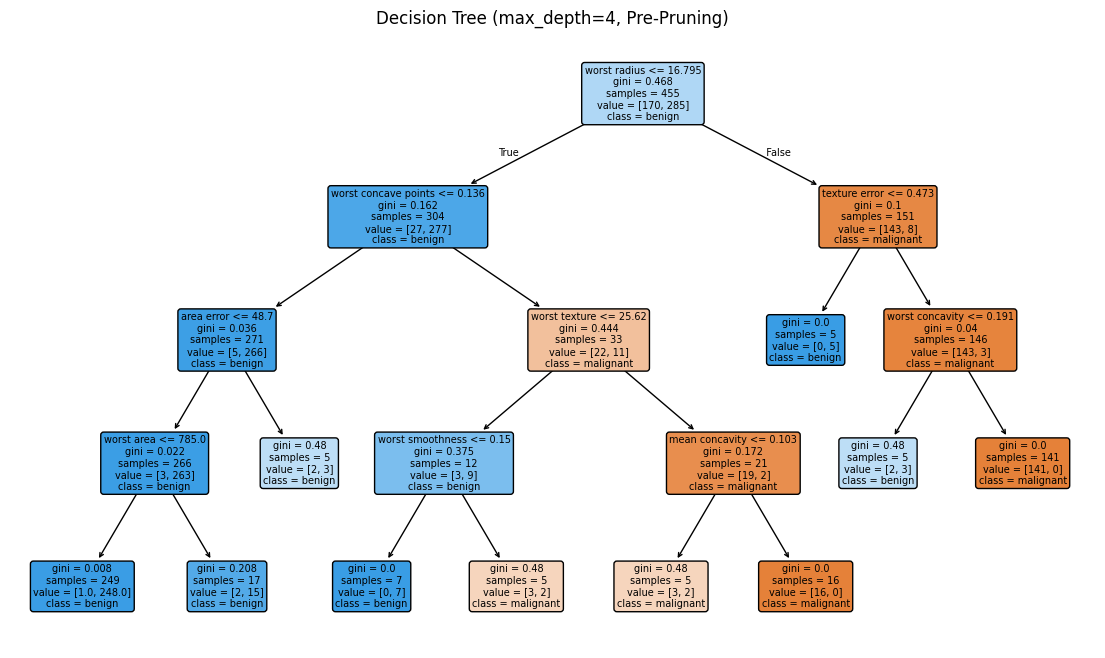

In [6]:
plt.figure(figsize=(14, 8))
plot_tree(tree_pruned, feature_names=data.feature_names, class_names=data.target_names,
          filled=True, rounded=True, fontsize=7)
plt.title("Decision Tree (max_depth=4, Pre-Pruning)")
plt.show()

## Bagian B — Latihan Praktikum

In [7]:
# Sesuai modul: cetak akurasi test tiap kombinasi
for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=min_leaf, random_state=42)
        model.fit(X_train, y_train)
        acc = accuracy_score(y_test, model.predict(X_test))
        print(f"max_depth={depth}, min_samples_leaf={min_leaf}: akurasi test={acc:.3f}")

max_depth=2, min_samples_leaf=1: akurasi test=0.895
max_depth=2, min_samples_leaf=5: akurasi test=0.895
max_depth=2, min_samples_leaf=10: akurasi test=0.904
max_depth=4, min_samples_leaf=1: akurasi test=0.939
max_depth=4, min_samples_leaf=5: akurasi test=0.921
max_depth=4, min_samples_leaf=10: akurasi test=0.947
max_depth=6, min_samples_leaf=1: akurasi test=0.912
max_depth=6, min_samples_leaf=5: akurasi test=0.930
max_depth=6, min_samples_leaf=10: akurasi test=0.947
max_depth=None, min_samples_leaf=1: akurasi test=0.912
max_depth=None, min_samples_leaf=5: akurasi test=0.930
max_depth=None, min_samples_leaf=10: akurasi test=0.947


In [8]:
# Ringkasan dalam bentuk tabel + CV pada train set
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for depth in [2, 4, 6, None]:
    for min_leaf in [1, 5, 10]:
        model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=min_leaf, random_state=42)
        cv = cross_val_score(model, X_train, y_train, cv=skf).mean()
        model.fit(X_train, y_train)
        baris.append({"max_depth": str(depth), "min_samples_leaf": min_leaf,
                      "akurasi_train": accuracy_score(y_train, model.predict(X_train)),
                      "akurasi_CV": cv,
                      "akurasi_test": accuracy_score(y_test, model.predict(X_test)),
                      "jumlah_leaf": model.get_n_leaves()})
hasil = pd.DataFrame(baris)
hasil["gap_train_test"] = hasil["akurasi_train"] - hasil["akurasi_test"]
print("Pivot akurasi test:")
display(hasil.pivot(index="max_depth", columns="min_samples_leaf", values="akurasi_test").loc[["2", "4", "6", "None"]].round(3))
print("Pivot akurasi CV (train set):")
display(hasil.pivot(index="max_depth", columns="min_samples_leaf", values="akurasi_CV").loc[["2", "4", "6", "None"]].round(3))
hasil.round(3)

Pivot akurasi test:


min_samples_leaf,1,5,10
max_depth,,,
2,0.895,0.895,0.904
4,0.939,0.921,0.947
6,0.912,0.930,0.947
None,0.912,0.930,0.947


Pivot akurasi CV (train set):


min_samples_leaf,1,5,10
max_depth,,,
2,0.932,0.927,0.923
4,0.930,0.932,0.914
6,0.925,0.927,0.914
None,0.916,0.927,0.914


,max_depth,min_samples_leaf,akurasi_train,akurasi_CV,akurasi_test,jumlah_leaf,gap_train_test
0,2,1,0.958,0.932,0.895,4,0.064
1,2,5,0.958,0.927,0.895,4,0.064
2,2,10,0.949,0.923,0.904,4,0.046
3,4,1,0.987,0.930,0.939,11,0.048
4,4,5,0.976,0.932,0.921,10,0.055
5,4,10,0.963,0.914,0.947,9,0.015
6,6,1,0.998,0.925,0.912,18,0.086
7,6,5,0.976,0.927,0.930,13,0.046
8,6,10,0.963,0.914,0.947,10,0.015
9,None,1,1.000,0.916,0.912,19,0.088


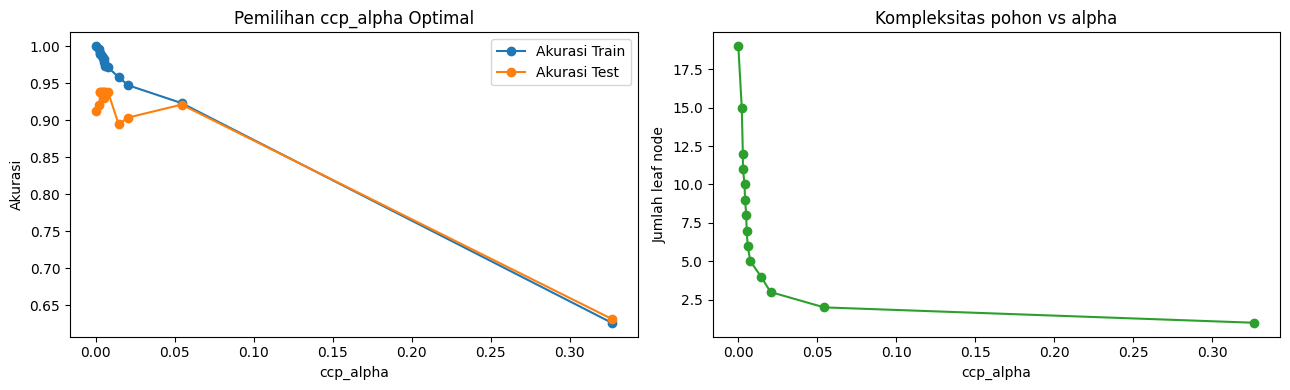

In [9]:
path = tree_full.cost_complexity_pruning_path(X_train, y_train)
akurasi_test, akurasi_train, n_leaf = [], [], []
for alpha in path.ccp_alphas:
    m = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42).fit(X_train, y_train)
    akurasi_test.append(accuracy_score(y_test, m.predict(X_test)))
    akurasi_train.append(accuracy_score(y_train, m.predict(X_train)))
    n_leaf.append(m.get_n_leaves())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(path.ccp_alphas, akurasi_train, marker='o', label="Akurasi Train")
ax[0].plot(path.ccp_alphas, akurasi_test, marker='o', label="Akurasi Test")
ax[0].set_xlabel("ccp_alpha"); ax[0].set_ylabel("Akurasi"); ax[0].set_title("Pemilihan ccp_alpha Optimal"); ax[0].legend()
ax[1].plot(path.ccp_alphas, n_leaf, marker='o', color="tab:green")
ax[1].set_xlabel("ccp_alpha"); ax[1].set_ylabel("Jumlah leaf node"); ax[1].set_title("Kompleksitas pohon vs alpha")
plt.tight_layout(); plt.show()

In [10]:
# (a) alpha dengan akurasi test tertinggi (bila seri, ambil alpha terbesar = pohon paling sederhana)
akurasi_test_arr = np.array(akurasi_test)
kandidat = np.where(akurasi_test_arr == akurasi_test_arr.max())[0]
idx_test = kandidat[-1]
alpha_test = path.ccp_alphas[idx_test]

# (b) alpha pilihan cross-validation pada train set (tanpa melihat test set)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = np.array([cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=42),
                                      X_train, y_train, cv=skf).mean() for a in path.ccp_alphas])
idx_cv = np.where(cv_scores == cv_scores.max())[0][-1]
alpha_cv = path.ccp_alphas[idx_cv]

baris = []
for nama, a in [("Tanpa pruning (alpha=0)", 0.0),
                ("alpha terbaik menurut TEST", alpha_test),
                ("alpha terbaik menurut CV", alpha_cv)]:
    m = DecisionTreeClassifier(ccp_alpha=a, random_state=42).fit(X_train, y_train)
    baris.append({"Pohon": nama, "ccp_alpha": a, "Jumlah leaf": m.get_n_leaves(), "Kedalaman": m.get_depth(),
                  "Akurasi train": accuracy_score(y_train, m.predict(X_train)),
                  "Akurasi test": accuracy_score(y_test, m.predict(X_test))})
pd.DataFrame(baris).round(4)

,Pohon,ccp_alpha,Jumlah leaf,Kedalaman,Akurasi train,Akurasi test
0,Tanpa pruning (alpha=0),0.0000,19,7,1.0000,0.9123
1,alpha terbaik menurut TEST,0.0076,5,3,0.9714,0.9386
2,alpha terbaik menurut CV,0.0053,7,4,0.9780,0.9298
